Data 620 - Project 2

Yana Rabkova

**Introduction**

Video presentation link: 

The dataset link: https://snap.stanford.edu/biodata/datasets/10018/10018-ChSe-Decagon.html 


In [ ]:
import pandas as pd
import networkx as nx
from networkx.algorithms import bipartite

# Load drug-side effect associations
df = pd.read_csv(
    "/Users/yanarabkova/Desktop/Yana/CUNY masters/DATA 620 - Web Analytics/Week 6 - Project 2/ChSe-Decagon_monopharmacy.csv.gz",
    compression="gzip"
)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.head())

# stitch - unique drug identifier, other variables related to side effect (individual side effect, side effect name)

Dataset shape: (174977, 3)
Columns: ['# STITCH', 'Individual Side Effect', 'Side Effect Name']
       # STITCH Individual Side Effect                Side Effect Name
0  CID003062316               C1096328     central nervous system mass
1  CID003062316               C0162830       Photosensitivity reaction
2  CID003062316               C1611725    leukaemic infiltration brain
3  CID003062316               C0541767  platelet adhesiveness abnormal
4  CID003062316               C0242973         Ventricular dysfunction


In [3]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Count unique drugs and side effects
print("\nUnique drugs:", df["# STITCH"].nunique())
print("Unique side effects:", df["Individual Side Effect"].nunique())

# Check duplicate drug-side effect relationships
print("\nDuplicate relationships:",
      df.duplicated(subset=["# STITCH", "Individual Side Effect"]).sum())

# Remove duplicate relationships
df_clean = df.drop_duplicates(
    subset=["# STITCH", "Individual Side Effect"]
).copy()

print("\nCleaned dataset shape:", df_clean.shape)

Missing values:
# STITCH                  0
Individual Side Effect    0
Side Effect Name          0
dtype: int64

Unique drugs: 639
Unique side effects: 10184

Duplicate relationships: 0

Cleaned dataset shape: (174977, 3)


In [4]:
import networkx as nx
from networkx.algorithms import bipartite

B = nx.Graph()

# Add drug nodes
drugs = df_clean["# STITCH"].unique()
B.add_nodes_from(drugs, bipartite=0, node_type="drug")

# Add side-effect nodes
side_effects = df_clean["Individual Side Effect"].unique()
B.add_nodes_from(side_effects, bipartite=1, node_type="side_effect")

# Add edges between drugs and side effects
B.add_edges_from(
    df_clean[["# STITCH", "Individual Side Effect"]].itertuples(
        index=False, name=None
    )
)

print("Total nodes:", B.number_of_nodes())
print("Total edges:", B.number_of_edges())
print("Is bipartite:", nx.is_bipartite(B))
print("Connected components:", nx.number_connected_components(B))

Total nodes: 10823
Total edges: 174977
Is bipartite: True
Connected components: 1


In [5]:
# Calculate degree for each drug
drug_degrees = pd.DataFrame({
    "Drug": drugs,
    "Degree": [B.degree(drug) for drug in drugs]
}).sort_values("Degree", ascending=False)

# Calculate degree for each side effect
side_effect_degrees = pd.DataFrame({
    "Side Effect ID": side_effects,
    "Degree": [B.degree(effect) for effect in side_effects]
}).sort_values("Degree", ascending=False)

# Add descriptive side effect names
effect_names = df_clean[
    ["Individual Side Effect", "Side Effect Name"]
].drop_duplicates(subset=["Individual Side Effect"])

side_effect_degrees = side_effect_degrees.merge(
    effect_names,
    left_on="Side Effect ID",
    right_on="Individual Side Effect",
    how="left"
)

print("Top 10 drugs:")
print(drug_degrees.head(10))

print("\nTop 10 side effects:")
print(side_effect_degrees[
    ["Side Effect Name", "Degree"]
].head(10))

Top 10 drugs:
             Drug  Degree
119  CID000068740    1550
403  CID000004674    1515
210  CID000005538    1229
211  CID000000444    1186
209  CID000005064    1045
492  CID000005090     979
635  CID000005376     947
137  CID000093860     927
600  CID000003902     896
508  CID000002818     871

Top 10 side effects:
                        Side Effect Name  Degree
0  general physical health deterioration     301
1                          hypoaesthesia     279
2                  mental status changes     278
3                       tooth extraction     276
4                     emotional distress     275
5     alanine aminotransferase increased     273
6                   condition aggravated     270
7                            pollakiuria     267
8               staphylococcal infection     266
9             blood creatinine increased     263


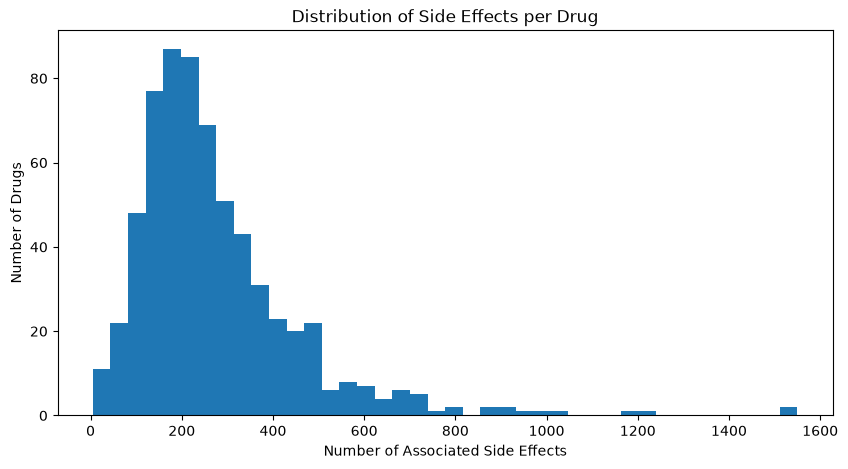

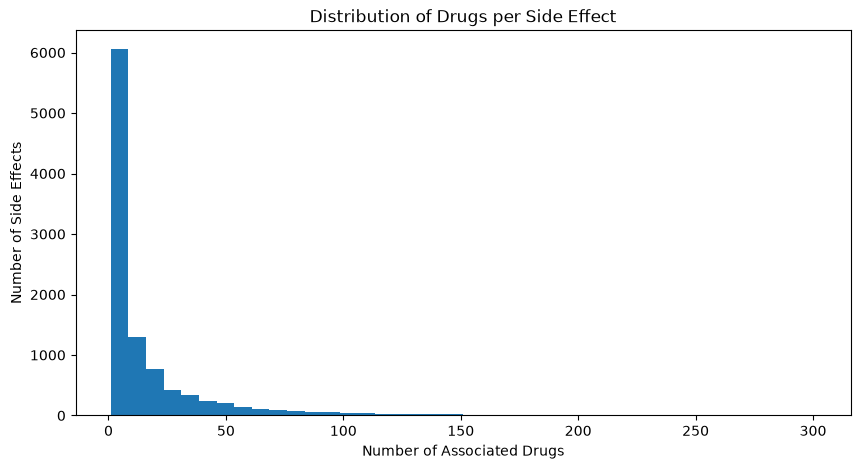

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(drug_degrees["Degree"], bins=40)
plt.title("Distribution of Side Effects per Drug")
plt.xlabel("Number of Associated Side Effects")
plt.ylabel("Number of Drugs")
plt.show()

plt.figure(figsize=(10, 5))
plt.hist(side_effect_degrees["Degree"], bins=40)
plt.title("Distribution of Drugs per Side Effect")
plt.xlabel("Number of Associated Drugs")
plt.ylabel("Number of Side Effects")
plt.show()

In [7]:

from networkx.algorithms import bipartite

# Create weighted drug projection
G_drugs = bipartite.weighted_projected_graph(
    B, drugs
)

print("Projected drug network:")
print("Nodes:", G_drugs.number_of_nodes())
print("Edges:", G_drugs.number_of_edges())

# Examine distribution of edge weights
weights = pd.Series([
    data["weight"]
    for _, _, data in G_drugs.edges(data=True)
])

print("\nShared side-effect counts:")
print(weights.describe())

print("\nWeight percentiles:")
print(weights.quantile([0.50, 0.75, 0.90, 0.95, 0.99]))


Projected drug network:
Nodes: 639
Edges: 202120

Shared side-effect counts:
count    202120.000000
mean         29.886429
std          26.606471
min           1.000000
25%          13.000000
50%          23.000000
75%          38.000000
max        1066.000000
dtype: float64

Weight percentiles:
0.50     23.0
0.75     38.0
0.90     59.0
0.95     78.0
0.99    128.0
dtype: float64


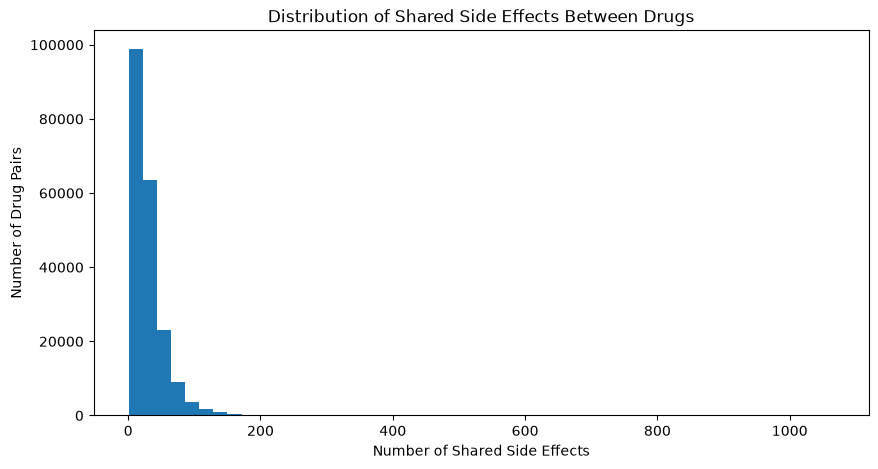

In [8]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(weights, bins=50)

plt.title("Distribution of Shared Side Effects Between Drugs")
plt.xlabel("Number of Shared Side Effects")
plt.ylabel("Number of Drug Pairs")

plt.show()


In [9]:

thresholds = weights.quantile(
    [0.75, 0.90, 0.95, 0.99]
).to_dict()

results = []

for percentile, threshold in thresholds.items():

    G_filtered = nx.Graph(
        (u, v, d)
        for u, v, d in G_drugs.edges(data=True)
        if d["weight"] >= threshold
    )

    components = list(nx.connected_components(G_filtered))

    results.append({
        "Percentile": percentile,
        "Threshold": threshold,
        "Nodes": G_filtered.number_of_nodes(),
        "Edges": G_filtered.number_of_edges(),
        "Components": len(components),
        "Largest Component": max(
            (len(c) for c in components),
            default=0
        )
    })

reduction_results = pd.DataFrame(results)
print(reduction_results)


   Percentile  Threshold  Nodes  Edges  Components  Largest Component
0        0.75       38.0    602  51790           1                602
1        0.90       59.0    532  20994           1                532
2        0.95       78.0    439  10137           1                439
3        0.99      128.0    229   2080           1                229


In [18]:

# Explore stricter weight thresholds
thresholds = [128, 150, 175, 200, 250, 300, 400, 500]

results = []

for threshold in thresholds:
    G_filtered = nx.Graph(
        (u, v, d)
        for u, v, d in G_drugs.edges(data=True)
        if d["weight"] >= threshold
    )

    components = sorted(
        nx.connected_components(G_filtered),
        key=len,
        reverse=True
    )

    results.append({
        "Threshold": threshold,
        "Nodes": G_filtered.number_of_nodes(),
        "Edges": G_filtered.number_of_edges(),
        "Components": len(components),
        "Largest Component": len(components[0]) if components else 0,
        "Second Largest": len(components[1]) if len(components) > 1 else 0
    })

pd.DataFrame(results)


,Threshold,Nodes,Edges,Components,Largest Component,Second Largest
0,128,229,2080,1,229,0
1,150,176,1169,3,169,5
2,175,114,657,1,114,0
3,200,88,395,1,88,0
4,250,52,163,1,52,0
5,300,33,80,2,31,2
6,400,13,22,1,13,0
7,500,6,9,1,6,0


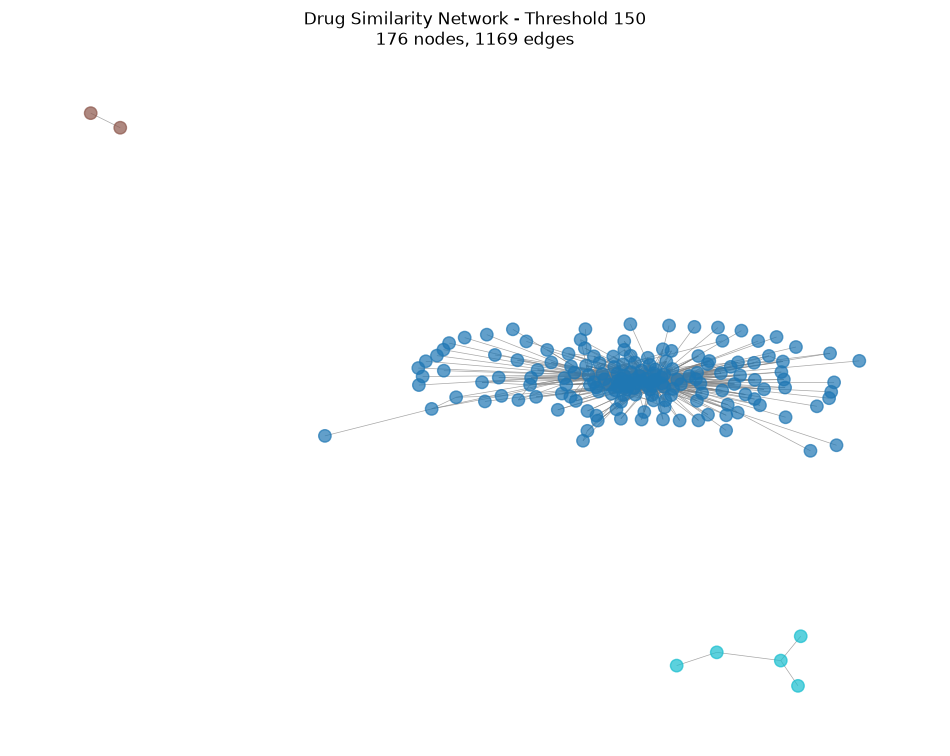

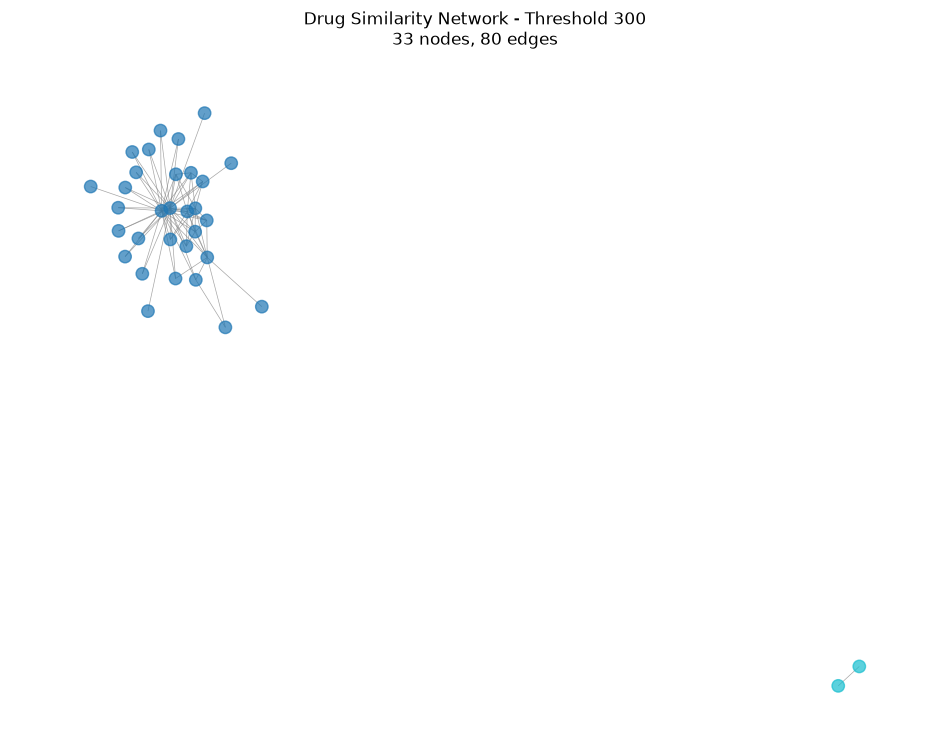

In [19]:

import matplotlib.pyplot as plt
import networkx as nx

def plot_island_network(G, threshold):

    G_filtered = nx.Graph(
        (u, v, d)
        for u, v, d in G.edges(data=True)
        if d["weight"] >= threshold
    )

    components = list(nx.connected_components(G_filtered))

    component_map = {}
    for i, component in enumerate(components):
        for node in component:
            component_map[node] = i

    node_colors = [
        component_map[node]
        for node in G_filtered.nodes()
    ]

    plt.figure(figsize=(12, 9))

    pos = nx.spring_layout(
        G_filtered,
        seed=42,
        k=0.5
    )

    nx.draw_networkx(
        G_filtered,
        pos,
        node_color=node_colors,
        cmap=plt.cm.tab10,
        node_size=80,
        edge_color="gray",
        alpha=0.7,
        with_labels=False,
        width=0.5
    )

    plt.title(
        f"Drug Similarity Network - Threshold {threshold}\n"
        f"{G_filtered.number_of_nodes()} nodes, "
        f"{G_filtered.number_of_edges()} edges"
    )

    plt.axis("off")
    plt.show()

plot_island_network(G_drugs, 150)
plot_island_network(G_drugs, 300)


In [22]:

effect_name_map = (
    df_clean
    .drop_duplicates("Individual Side Effect")
    .set_index("Individual Side Effect")["Side Effect Name"]
    .to_dict()
)

# Examine the smaller components
for i, component in enumerate(components, 1):
    print(f"\nComponent {i}: {len(component)} drugs")

    if len(component) <= 10:
        for drug in sorted(component):
            print(drug)

# Examine the shared side effects within each small component
for i, component in enumerate(components, 1):
    if len(component) <= 10:
        drug_list = list(component)

        common_effects = set(B.neighbors(drug_list[0]))

        for drug in drug_list[1:]:
            common_effects &= set(B.neighbors(drug))

        print(f"\nComponent {i}:")
        print("Side effects common to ALL drugs:",
              len(common_effects))

        for effect in sorted(common_effects)[:15]:
            print(effect_name_map.get(effect, effect))



Component 1: 6 drugs
CID000002713
CID000003902
CID000004674
CID000004730
CID000005376
CID000068740

Component 1:
Side effects common to ALL drugs: 184
actinomycosis
alveoloplasty
bone graft
central venous catheterisation
osteomyelitis chronic
debridement
dental care
dental fistula
dental implantation
sensitivity of teeth
dysgeusia
foot deformity
gingival hyperplasia
hand-foot-and-mouth disease
hyperbaric oxygen therapy
